# ShiftAware · results and analysis

**EE6405 group project · EmotionShift · workstream #6**

ShiftAware reads a dialogue turn by turn. RoBERTa-base encodes each utterance; a causal dynamics
module keeps one memory per speaker and one for the conversation, attends to what the other speakers
said, and mixes a prior from the speaker's own history with the evidence of the current utterance.
A second head predicts whether the speaker's emotion shifts at this turn, and that supervision is the
idea under test (H3 in the proposal).

This notebook does not train. It recomputes everything from the committed outputs:

1. Variant selection on **dev** (never test)
2. Test scores from `predictions/`, next to B1 (TF-IDF) and B3 (RoBERTa, utterance only)
3. Scores on first / stable / shift turns, with paired tests against B3
4. The shift head: how well `shift_prob` separates shift from stable turns
5. Efficiency (E9) and what is still missing

Training: `scripts/train_shiftaware.py` (GPU). Checkpoints are not in Git.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from emotionshift.data.labels import EMOTIONS
from emotionshift.eval.metrics import HEADLINE, scores
from emotionshift.eval.plots import SERIES, INK_2
from scripts import summarize_all as S

SPLIT = {"meld": "test", "dailydialog": "test_dedup"}
pd.set_option("display.precision", 2)

## 1 · Variant selection on dev

Two variants have five seeds: the base model (`shiftaware`) and one with square-root inverse class
weights (`shiftaware_cw-sqrt`). Each seed's best epoch was already chosen on dev. Here we pick the
variant with the higher mean dev headline score, which must agree with
`reports/shiftaware/selection.md`. Single-seed and three-seed variants stay exploratory.

In [2]:
rows = []
for variant in ["shiftaware", "shiftaware_cw-sqrt"]:
    for dataset in SPLIT:
        for path in sorted((ROOT / "reports" / variant / dataset).glob("seed*/summary.json")):
            s = json.loads(path.read_text())
            rows.append({"variant": variant, "dataset": dataset, "seed": s["seed"],
                         "dev": 100 * s["dev"][HEADLINE[dataset]], "dirty_tree": s["git"]["dirty"]})
dev = pd.DataFrame(rows)
table = dev.groupby(["dataset", "variant"])["dev"].agg(["count", "mean", "std"])
display(table)
chosen = table["mean"].groupby(level=0).idxmax().map(lambda k: k[1]).to_dict()
print("chosen on dev:", chosen)
assert chosen == {d: S.BY_KEY["shiftaware"].prefix[d] for d in SPLIT}, "disagrees with selection.md"
print("runs from a dirty working tree:", int(dev.dirty_tree.sum()), "of", len(dev))

count   mean   std
dataset     variant                               
dailydialog shiftaware              5  60.99  0.71
            shiftaware_cw-sqrt      5  58.49  0.84
meld        shiftaware              5  59.94  0.61
            shiftaware_cw-sqrt      5  60.78  1.02

chosen on dev: {'dailydialog': 'shiftaware', 'meld': 'shiftaware_cw-sqrt'}
runs from a dirty working tree: 13 of 20


## 2 · Test scores

All numbers below come from `predictions/`, aligned row by row with B1. Mean ± sample SD over seeds.

In [3]:
data = {d: S.load(d, s) for d, s in SPLIT.items()}
rows = []
for dataset, loaded in data.items():
    for key in ["b1", "b3", "shiftaware"]:
        seeds, codes = loaded.preds[key]
        for seed, code in zip(seeds, codes):
            pred = [EMOTIONS[i] for i in code]
            sc = scores(loaded.base["emotion"], pred)
            rows.append({"dataset": dataset, "model": key, "seed": seed,
                         **{m: 100 * sc[m] for m in ["weighted_f1", "macro_f1", "micro_f1_no_neutral"]}})
per_seed = pd.DataFrame(rows)
per_seed.groupby(["dataset", "model"]).agg(["mean", "std"]).drop(columns="seed")

weighted_f1       macro_f1       micro_f1_no_neutral  \
                              mean   std     mean   std                mean   
dataset     model                                                             
dailydialog b1               83.88  0.00    46.16  0.00               53.03   
            b3               84.80  0.03    39.69  1.09               55.34   
            shiftaware       85.42  0.36    45.09  5.34               57.39   
meld        b1               56.78  0.00    38.39  0.00               40.91   
            b3               62.85  0.31    40.56  0.80               49.88   
            shiftaware       62.52  0.57    46.33  0.80               49.64   

                              
                         std  
dataset     model             
dailydialog b1          0.00  
            b3          0.39  
            shiftaware  0.71  
meld        b1          0.00  
            b3          0.61  
            shiftaware  0.81

On MELD, ShiftAware matches B3 on weighted-F1 but is clearly higher on macro-F1: the class
weights trade a little accuracy on *neutral* for the rare emotions. On DailyDialog it is ahead of B3
on the headline (micro-F1 without neutral), but macro-F1 varies a lot across seeds (one seed is far
lower), so that gain is less stable.

## 3 · First, stable and shift turns

H3 is about **shift** turns: the speaker's emotion differs from their previous turn. Paired
comparisons use all five seed pairs; the CI resamples whole test dialogues and the p-value is
approximate randomization with dialogue-level swaps (`scripts/summarize_all.py`). The pre-registered
comparison is against the *context* RoBERTa (#5), which is not submitted yet, so B3 stands in here.

In [4]:
rng = np.random.default_rng(0)
out = []
for dataset, loaded in data.items():
    metric = HEADLINE[dataset]
    n_d = int(loaded.dialogue.max()) + 1
    for group in ["first", "stable", "shift"]:
        mask = (loaded.base["stratum"] == group).to_numpy()
        counts = {k: S.dialogue_counts(loaded.gold, loaded.preds[k][1], loaded.dialogue, mask, n_d)
                  for k in ["b1", "b3", "shiftaware"]}
        row = {"dataset": dataset, "group": group, "n": int(mask.sum())}
        for k, c in counts.items():
            row[k] = 100 * S.batch_scores(c.sum(0).reshape(-1, 7, 7))[metric].mean()
        t = S.paired_test(counts["b3"], counts["shiftaware"], metric, 2000, 5000, rng)
        row["ShiftAware - B3"] = f"{100*t['diff']:+.2f} [{100*t['ci_low']:+.2f}, {100*t['ci_high']:+.2f}]"
        row["p"] = t["p"]
        out.append(row)
strata = pd.DataFrame(out)
strata

,dataset,group,n,b1,b3,shiftaware,ShiftAware - B3,p
0,meld,first,746,62.17,65.18,64.25,"-0.93 [-2.94, +1.03]",3.57e-01
1,meld,stable,861,62.12,69.73,70.47,"+0.74 [-1.61, +3.20]",5.29e-01
2,meld,shift,1003,49.15,55.91,54.95,"-0.96 [-2.92, +1.03]",3.68e-01
3,dailydialog,first,1782,50.94,52.67,55.02,"+2.35 [-0.34, +5.07]",9.58e-02
4,dailydialog,stable,4295,35.87,37.89,45.00,"+7.11 [+4.54, +9.59]",2.00e-04
5,dailydialog,shift,942,70.50,71.46,69.34,"-2.12 [-3.97, -0.22]",2.80e-02


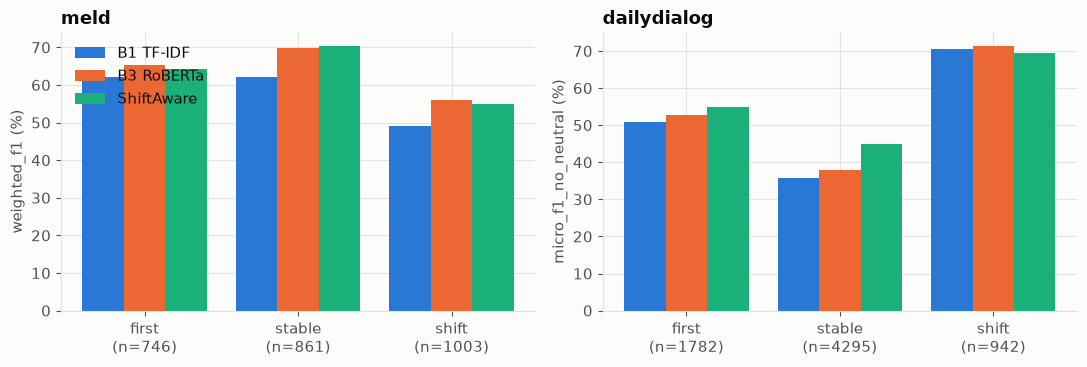

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, dataset in zip(axes, SPLIT):
    sub = strata[strata.dataset == dataset]
    x = np.arange(len(sub))
    for i, (key, name) in enumerate([("b1", "B1 TF-IDF"), ("b3", "B3 RoBERTa"), ("shiftaware", "ShiftAware")]):
        ax.bar(x + (i - 1) * 0.27, sub[key], 0.27, color=SERIES[i], label=name)
    ax.set_xticks(x, [f"{g}\n(n={n})" for g, n in zip(sub.group, sub.n)])
    ax.set_title(dataset); ax.set_ylabel(f"{HEADLINE[dataset]} (%)")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

**Reading.** ShiftAware's gain over B3 is on **stable** turns (clearly on DailyDialog), not on
shift turns: on MELD shift turns it is about one point below B3 with a CI that includes 0, and on
DailyDialog shift turns it is significantly below B3. So far the data do not support H3's mechanism
(explicit shift supervision helps exactly where the emotion changes). That is a reportable negative
result; the decisive test still needs the context RoBERTa (#5) and an ablation without the shift head
on MELD.

## 4 · The shift head

`shift_prob` is the head's probability that this turn is a shift. It sees the current utterance, so
this is shift *detection*, not forecasting (H4 needs history-only forecasts, which were not exported
for MELD or DailyDialog). Scored on stable and shift turns only (first turns have no previous emotion).

In [6]:
rows = []
for dataset in SPLIT:
    prefix = S.BY_KEY["shiftaware"].prefix[dataset]
    for path in S._files(prefix, dataset, SPLIT[dataset]):
        df = pd.read_csv(path)
        d = df[df["stratum"].isin(["stable", "shift"])]
        y = (d["stratum"] == "shift").astype(int)
        rows.append({"dataset": dataset, "seed": int(df["seed"].iloc[0]), "n": len(d),
                     "shift_rate": 100 * y.mean(), "auroc": 100 * roc_auc_score(y, d["shift_prob"])})
head = pd.DataFrame(rows)
head.groupby("dataset")[["n", "shift_rate", "auroc"]].agg(["mean", "std"])

n      shift_rate       auroc      
               mean  std       mean  std   mean   std
dataset                                              
dailydialog  5237.0  0.0      17.99  0.0  84.17  0.24
meld         1864.0  0.0      53.81  0.0  74.75  0.54

The head separates shift from stable turns well above chance (AUROC 50), yet that skill does not
turn into better emotion labels on shift turns (section 3). One reading: the head learns *that*
something changes, but the emotion classifier still leans on the speaker prior on those turns.

## 5 · Efficiency (E9) and open items

Checkpoints are not in Git, so `scripts/measure_shiftaware_efficiency.py` times the same architecture
with untrained weights on a laptop CPU (size and latency do not depend on the weight values).

In [7]:
eff = json.loads((ROOT / "reports/shiftaware/efficiency.json").read_text())["efficiency"]
print(f"parameters: {eff['parameters']:,} (encoder {eff['parameters_by_part']['encoder']:,}, "
      f"dynamics {eff['parameters_by_part']['dynamics']:,})")
print(f"file size: {eff['model_file_mb']} MB")
for k in ["latency_one_utterance", "latency_amortized"]:
    v = eff[k]; print(f"{v['what']}: median {v['median_ms']:.1f} ms, p95 {v['p95_ms']:.1f} ms")
print("machine:", eff["machine"]["platform"], "| threads:", eff["threads"])

parameters: 127,217,569 (encoder 124,645,632, dynamics 2,571,937)
file size: 508.96 MB
label one new turn by re-running its dialogue prefix (live demo): median 50.1 ms, p95 133.7 ms
whole dialogue in one call, divided by its turns (offline): median 10.1 ms, p95 21.7 ms
machine: macOS-27.0.1-arm64-arm-64bit | threads: 4


Labelling a new turn stays under the 300 ms demo budget (R5) even when the whole prefix is
re-encoded. The dynamics module adds about 2% parameters on top of RoBERTa-base.

**Still missing** (not reproducible without the owner's checkpoints or new GPU runs):
- Training time per seed (not logged in the per-seed summaries)
- The inertia-gate alpha column for the demo
- A MELD ablation without the shift head (only EmoWOZ variants exist), which is what isolates H3
- History-only forecasts on MELD / DailyDialog for H4